# Seleção de regiões para novos poços de petróleo
### Predição de reservas, análise de rentabilidade e avaliação de risco

**Projeto de Data Science | TripleTen — Sprint 10 | Python · Pandas · Scikit-learn · Bootstrapping**

> **Recomendação:** desenvolver os poços na **Região 1**. Embora a Região 0 apresente o maior lucro na seleção inicial dos 200 poços, somente a Região 1 atende ao limite de risco estabelecido: **1,5% de probabilidade estimada de prejuízo** (limite inferior a 2,5%), com **lucro médio simulado de aproximadamente US$ 4,56 milhões**.

Esta análise foi desenvolvida com dados sintéticos para demonstrar como previsões de *machine learning* podem orientar decisões de investimento sujeitas a restrições de risco.

## Objetivo e contexto de negócio

A empresa fictícia de mineração **OilyGiant** deseja escolher uma entre três regiões para desenvolver novos poços de petróleo. O problema não é apenas identificar os locais com mais reservas, mas **selecionar a região que ofereça o melhor lucro esperado dentro de um limite aceitável de risco financeiro**.

**Critérios do projeto**

- Avaliar **500 pontos** de exploração e selecionar os **200 com maiores reservas previstas**.
- Considerar orçamento de **US$ 100 milhões** para desenvolver os 200 poços.
- Considerar receita de **US$ 4,50 por barril**, equivalente a **US$ 4.500 por unidade** da variável `product` (mil barris).
- Aceitar somente regiões cuja **probabilidade estimada de prejuízo seja inferior a 2,5%**.
- Entre as elegíveis, escolher a região com maior lucro médio.
- Utilizar **regressão linear**, conforme a restrição do estudo.

### Dados disponíveis

São três conjuntos sintéticos de exploração geológica, cada um com 100.000 observações. Todos possuem `id` (identificador do poço), `f0`, `f1`, `f2` (características geológicas sem descrição física) e `product` (volume das reservas, em **milhares de barris**).

Fontes: [geo_data_0.csv](https://practicum-content.s3.us-west-1.amazonaws.com/datasets/geo_data_0.csv), [geo_data_1.csv](https://practicum-content.s3.us-west-1.amazonaws.com/datasets/geo_data_1.csv) e [geo_data_2.csv](https://practicum-content.s3.us-west-1.amazonaws.com/datasets/geo_data_2.csv).

**Estratégia:** análise de qualidade dos dados → divisão treino/validação (75%/25%) → pipelines de regressão linear → seleção dos 200 poços → 1.000 amostras bootstrap por região → comparação de lucro e risco.

## 1. Carregamento e verificação dos dados

O notebook procura os CSVs na pasta `data/` do repositório e, como alternativa, em `../datasets/`, usada no ambiente original. O diretório selecionado deve conter os três arquivos.

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [ ]:
data_dir = next(
    (path for path in [Path("data"), Path("../datasets")] if (path / "geo_data_0.csv").exists()),
    None,
)
if data_dir is None:
    raise FileNotFoundError(
        "Os arquivos não foram encontrados. Coloque geo_data_0.csv, "
        "geo_data_1.csv e geo_data_2.csv em data/ ou ../datasets/."
    )

geo_data_0 = pd.read_csv(data_dir / "geo_data_0.csv")
geo_data_1 = pd.read_csv(data_dir / "geo_data_1.csv")
geo_data_2 = pd.read_csv(data_dir / "geo_data_2.csv")
region_datasets = {0: geo_data_0, 1: geo_data_1, 2: geo_data_2}

In [ ]:
data_quality = pd.DataFrame(
    [
        {
            "Região": f"Região {region}",
            "Observações": len(df),
            "Valores ausentes": int(df.isna().sum().sum()),
            "Linhas duplicadas": int(df.duplicated().sum()),
            "IDs repetidos": int(df["id"].duplicated().sum()),
            "Reserva média (mil barris)": df["product"].mean(),
        }
        for region, df in region_datasets.items()
    ]
)
display(data_quality.round(2))

Região,Observações,Valores ausentes,Linhas duplicadas,IDs repetidos,Reserva média (mil barris)
Região 0,100000,0,0,10,92.50
Região 1,100000,0,0,4,68.83
Região 2,100000,0,0,4,95.00


**Diagnóstico.** Não há valores ausentes ou linhas inteiramente duplicadas. Há, no entanto, **10 IDs repetidos na Região 0 e 4 em cada uma das Regiões 1 e 2**. As observações associadas a esses IDs apresentam características diferentes; por isso, foram preservadas, como no projeto aprovado. Em uma aplicação real, seria necessário verificar com a fonte dos dados se representam poços distintos ou erros de identificação.

O identificador `id` não será usado como variável preditora. A correspondência entre observações reais e previstas será preservada pelo **índice da linha**.

## 2. Modelagem preditiva das reservas

Cada região recebe um modelo de **regressão linear** próprio. Os dados são divididos aleatoriamente em **75% para treinamento e 25% para validação**, com semente fixa para reprodução dos resultados.

A transformação com `StandardScaler` ocorre dentro de uma `Pipeline`: o ajuste dos parâmetros de escala acontece **apenas no treinamento**, evitando vazamento de informações da validação. Embora a padronização não seja necessária para regressão linear comum, ela demonstra uma estrutura segura e reutilizável de pré-processamento.

A métrica de avaliação é a **raiz do erro quadrático médio (REQM / RMSE)**, medida na mesma unidade da variável-alvo: milhares de barris.

In [ ]:
def features_target_split(
    data_df: pd.DataFrame, non_training_columns: list[str], target_column: str
) -> tuple[pd.DataFrame, pd.Series]:
    """Separa características preditoras e variável-alvo."""
    features = data_df.drop(columns=non_training_columns + [target_column])
    target = data_df[target_column]
    return features, target


def model_pipe(num_columns: list[str]) -> Pipeline:
    """Cria pipeline de padronização e regressão linear."""
    preprocessor = ColumnTransformer(
        transformers=[("num_preprocess", StandardScaler(), num_columns)],
        remainder="passthrough",
    )
    return Pipeline(
        [("column_transform", preprocessor), ("model", LinearRegression())]
    )


def region_workflow(
    data_df: pd.DataFrame,
    non_training_columns: list[str],
    feature_columns: list[str],
    target_column: str,
    test_size: float,
    random_state: int,
) -> tuple[pd.Series, pd.Series, pd.DataFrame, float, float, Pipeline]:
    """Treina e valida um modelo, preservando índices e IDs das previsões."""
    features, target = features_target_split(
        data_df, non_training_columns, target_column
    )
    features_train, features_valid, target_train, target_valid = train_test_split(
        features, target, test_size=test_size, random_state=random_state
    )

    pipe = model_pipe(feature_columns)
    pipe.fit(features_train, target_train)

    predicted_valid = pd.Series(
        pipe.predict(features_valid), index=target_valid.index
    )
    validation_results = pd.DataFrame(
        {"actual_product": target_valid, "predicted_product": predicted_valid}
    ).merge(
        data_df[non_training_columns],
        how="left",
        left_index=True,
        right_index=True,
    )

    mean_predicted = predicted_valid.mean()
    rmse = mean_squared_error(target_valid, predicted_valid) ** 0.5
    return target_valid, predicted_valid, validation_results, mean_predicted, rmse, pipe

In [ ]:
split_state = 12345
valid_size = 0.25
non_training_columns = ["id"]
feature_columns = ["f0", "f1", "f2"]
target_column = "product"

(
    target_valid_0, predicted_valid_0, validation_results_0,
    mean_predicted_0, rmse_0, pipe_0,
) = region_workflow(
    geo_data_0, non_training_columns, feature_columns,
    target_column, valid_size, split_state,
)
(
    target_valid_1, predicted_valid_1, validation_results_1,
    mean_predicted_1, rmse_1, pipe_1,
) = region_workflow(
    geo_data_1, non_training_columns, feature_columns,
    target_column, valid_size, split_state,
)
(
    target_valid_2, predicted_valid_2, validation_results_2,
    mean_predicted_2, rmse_2, pipe_2,
) = region_workflow(
    geo_data_2, non_training_columns, feature_columns,
    target_column, valid_size, split_state,
)

validation_by_region = {
    0: validation_results_0,
    1: validation_results_1,
    2: validation_results_2,
}

In [ ]:
model_summary = pd.DataFrame(
    {
        "Região": ["Região 0", "Região 1", "Região 2"],
        "Reserva média prevista (mil barris)": [
            mean_predicted_0, mean_predicted_1, mean_predicted_2
        ],
        "REQM (mil barris)": [rmse_0, rmse_1, rmse_2],
    }
)
display(model_summary.round(2))

Região,Reserva média prevista (mil barris),REQM (mil barris)
Região 0,92.59,37.58
Região 1,68.73,0.89
Região 2,94.97,40.03


**Interpretação.** As regiões 0 e 2 têm maiores reservas médias previstas, mas apresentam erros de previsão substancialmente maiores. A Região 1 tem a menor reserva média prevista (**68,73 mil barris**) e o menor REQM (**0,89 mil barris**). Isso indica melhor ajuste de previsão no conjunto de validação, **não uma garantia de desempenho futuro**.

Essas métricas isoladamente não resolvem o problema de negócio: é necessário selecionar os poços com maiores previsões e medir os efeitos dessa seleção sobre lucro e risco.

## 3. Premissas econômicas e ponto de equilíbrio

A receita estimada depende do volume de reservas efetivamente encontrado nos poços escolhidos. O lucro é dado por:

\[
\text{Lucro} = (\text{Reservas reais em mil barris} \times 4.500) - 100.000.000
\]

Para recuperar US$ 100 milhões com 200 poços, seria necessário produzir em média **111,11 mil barris por poço**, sob as premissas simplificadas de preço e custo do projeto.

In [ ]:
oil_well_num = 200
budget = 100_000_000  # US$ 100 milhões para o desenvolvimento dos 200 poços
product_unit_rev = 4_500  # US$ por unidade de product (1.000 barris)
loss_risk_max = 0.025  # o risco deve ser estritamente inferior a 2,5%

product_mean_min = budget / oil_well_num / product_unit_rev
print(f"Ponto de equilíbrio por poço: {product_mean_min:.2f} mil barris")
display(
    data_quality[["Região", "Reserva média (mil barris)"]].round(2)
)

Ponto de equilíbrio por poço: 111.11 mil barris


Nenhuma das três regiões supera esse volume médio de equilíbrio quando se consideram **todos os poços indistintamente**. A seleção direcionada dos 200 poços com maiores reservas previstas pode, contudo, produzir lucro positivo. Por isso, a análise passa a avaliar os poços escolhidos pelo modelo, não uma amostra aleatória de 200 poços.

## 4. Rentabilidade da seleção dos 200 melhores poços

Em cada região, classificamos as observações do conjunto de validação pelas **reservas previstas** e selecionamos as 200 maiores. O lucro dessa seleção é calculado com as **reservas reais** correspondentes, simulando a comparação posterior entre decisão e resultado observado.

In [ ]:
def region_predicted_revenue_profit(
    region_data: pd.DataFrame,
    sort_column: str,
    target_column: str,
    count: int,
    budget: float,
    product_unit_rev: float,
) -> tuple[pd.DataFrame, float, float]:
    """Seleciona os poços por previsão e calcula receita e lucro pelos valores reais."""
    top_wells = region_data.sort_values(
        by=sort_column, ascending=False
    ).head(count)
    target_product_sum = top_wells[target_column].sum()
    potential_revenue = target_product_sum * product_unit_rev
    profit = potential_revenue - budget
    return top_wells, potential_revenue, profit

In [ ]:
top_wells_0, potential_revenue_0, profit_0 = region_predicted_revenue_profit(
    validation_results_0, "predicted_product", "actual_product",
    oil_well_num, budget, product_unit_rev,
)
top_wells_1, potential_revenue_1, profit_1 = region_predicted_revenue_profit(
    validation_results_1, "predicted_product", "actual_product",
    oil_well_num, budget, product_unit_rev,
)
top_wells_2, potential_revenue_2, profit_2 = region_predicted_revenue_profit(
    validation_results_2, "predicted_product", "actual_product",
    oil_well_num, budget, product_unit_rev,
)

In [ ]:
top_wells_summary = pd.DataFrame(
    {
        "Região": ["Região 0", "Região 1", "Região 2"],
        "Receita (US$ milhões)": [
            potential_revenue_0, potential_revenue_1, potential_revenue_2
        ],
        "Lucro (US$ milhões)": [profit_0, profit_1, profit_2],
    }
)
top_wells_summary.iloc[:, 1:] /= 1_000_000
display(top_wells_summary.round(2))

Região,Receita (US$ milhões),Lucro (US$ milhões)
Região 0,133.21,33.21
Região 1,124.15,24.15
Região 2,127.10,27.10


**Resultado preliminar.** A Região 0 apresenta o maior lucro observado na seleção específica de 200 poços (**US$ 33,21 milhões**). Porém, esse valor depende de uma única seleção, feita a partir do conjunto de validação. Ele não quantifica a variabilidade de lucro se outro conjunto de 500 pontos fosse considerado.

Para comparar alternativas de investimento de maneira consistente com a restrição de risco, é preciso simular diferentes conjuntos de candidatos.

## 5. Distribuição de lucros e risco de prejuízo: bootstrapping

Para cada região, o procedimento de *bootstrapping* é:

1. Sortear **500 observações com reposição** entre os resultados de validação.
2. Selecionar as **200 maiores reservas previstas** nessa amostra.
3. Calcular a receita pelas reservas **reais** das 200 selecionadas e subtrair o orçamento.
4. Repetir o procedimento **1.000 vezes** para obter uma distribuição empírica de lucros.
5. Calcular lucro médio, quantis de 2,5% e 97,5% e fração de simulações com lucro negativo.

**Interpretação estatística:** os quantis delimitam a faixa central de 95% dos **cenários simulados de lucro**. Não devem ser confundidos automaticamente com um intervalo de confiança de 95% para a **média** do lucro. A estimativa de risco é condicional aos dados, modelos e hipóteses da simulação.

In [ ]:
confidence_interval = (0.025, 0.975)
bootstrap_sample_size = 500
bootstrap_samples = 1_000


def profit_distribution(
    region_data: pd.DataFrame,
    sort_column: str,
    target_column: str,
    bootstrap_samples: int,
    bootstrap_sample_size: int,
    top_well_num: int,
    confidence_interval: tuple[float, float],
    budget: float,
    product_unit_rev: float,
    random_state: int = 12345,
) -> tuple[float, float, float, float, pd.Series]:
    """Simula a distribuição de lucros mantendo o processo de seleção 500→200."""
    bootstrap_state = np.random.RandomState(random_state)
    profits = []

    for _ in range(bootstrap_samples):
        subsample = region_data.sample(
            n=bootstrap_sample_size, replace=True, random_state=bootstrap_state
        )
        sorted_subsample = subsample.sort_values(
            by=sort_column, ascending=False
        )
        top_subsample = sorted_subsample.head(top_well_num)
        total_revenue = top_subsample[target_column].sum() * product_unit_rev
        profits.append(total_revenue - budget)

    profits = pd.Series(profits)
    lower = profits.quantile(confidence_interval[0])
    upper = profits.quantile(confidence_interval[1])
    profit_mean = profits.mean()
    loss_proba = (profits < 0).mean()
    return profit_mean, lower, upper, loss_proba, profits

In [ ]:
profit_mean_0, lower_0, upper_0, loss_proba_0, profits_0 = profit_distribution(
    validation_results_0, "predicted_product", "actual_product",
    bootstrap_samples, bootstrap_sample_size, oil_well_num,
    confidence_interval, budget, product_unit_rev,
)
profit_mean_1, lower_1, upper_1, loss_proba_1, profits_1 = profit_distribution(
    validation_results_1, "predicted_product", "actual_product",
    bootstrap_samples, bootstrap_sample_size, oil_well_num,
    confidence_interval, budget, product_unit_rev,
)
profit_mean_2, lower_2, upper_2, loss_proba_2, profits_2 = profit_distribution(
    validation_results_2, "predicted_product", "actual_product",
    bootstrap_samples, bootstrap_sample_size, oil_well_num,
    confidence_interval, budget, product_unit_rev,
)

In [ ]:
bootstrap_summary = pd.DataFrame(
    {
        "Região": ["Região 0", "Região 1", "Região 2"],
        "Lucro médio (US$ milhões)": [
            profit_mean_0, profit_mean_1, profit_mean_2
        ],
        "Limite inferior 2,5% (US$ milhões)": [lower_0, lower_1, lower_2],
        "Limite superior 97,5% (US$ milhões)": [upper_0, upper_1, upper_2],
        "Risco de prejuízo (%)": [
            100 * loss_proba_0, 100 * loss_proba_1, 100 * loss_proba_2
        ],
        "Aprovada no limite de risco": [
            "Sim" if risk < loss_risk_max else "Não"
            for risk in (loss_proba_0, loss_proba_1, loss_proba_2)
        ],
    }
)
bootstrap_summary.iloc[:, 1:4] /= 1_000_000
display(bootstrap_summary.round(2))

Região,Lucro médio (US$ milhões),"Limite inferior 2,5% (US$ milhões)","Limite superior 97,5% (US$ milhões)",Risco de prejuízo (%),Aprovada no limite de risco
Região 0,3.96,-1.11,9.10,6.9,Não
Região 1,4.56,0.34,8.52,1.5,Sim
Região 2,4.04,-1.63,9.50,7.6,Não


### Visualização da rentabilidade e do risco

O primeiro gráfico compara o lucro médio e a faixa central de 95% dos lucros simulados. O segundo destaca a restrição de **2,5%** de probabilidade de prejuízo. Os gráficos também são salvos na pasta `figures/` para possível utilização posterior no README.

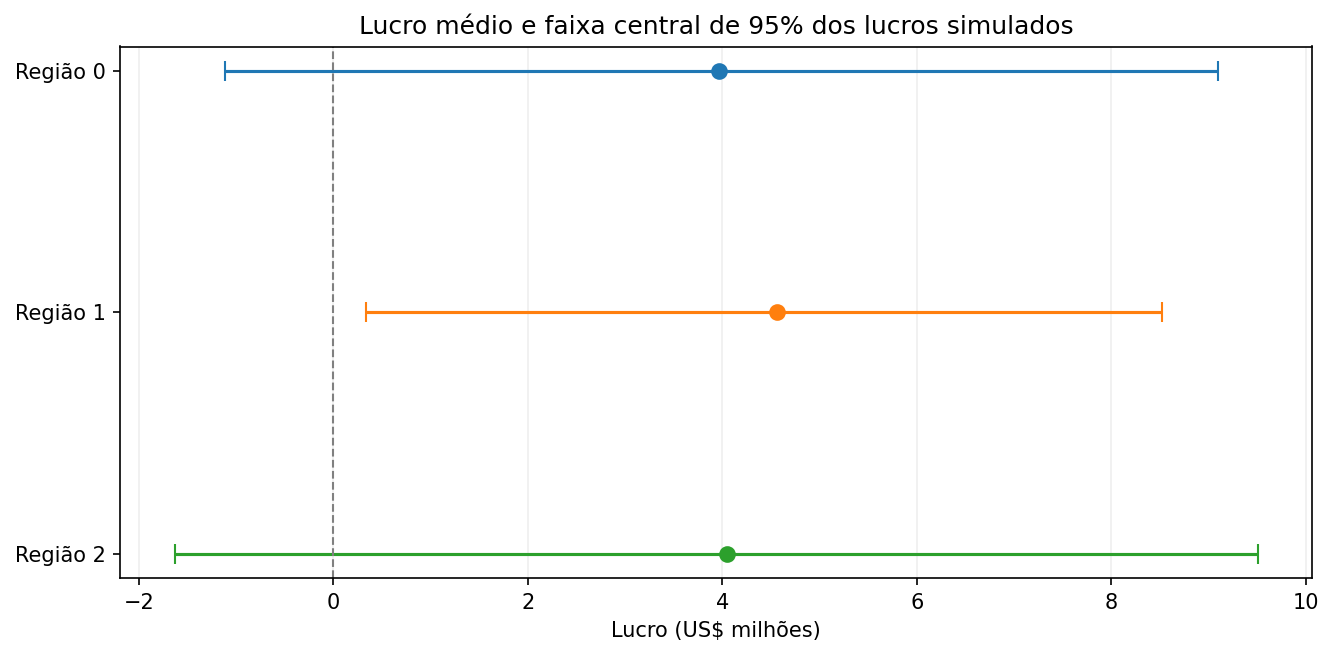

In [ ]:
figures_dir = Path("figures")
figures_dir.mkdir(exist_ok=True)

fig, ax = plt.subplots(figsize=(9, 4.5))
for index, row in bootstrap_summary.iterrows():
    mean = row["Lucro médio (US$ milhões)"]
    lower = row["Limite inferior 2,5% (US$ milhões)"]
    upper = row["Limite superior 97,5% (US$ milhões)"]
    ax.errorbar(
        mean, index,
        xerr=[[mean - lower], [upper - mean]],
        fmt="o", capsize=5, markersize=7,
    )
ax.axvline(0, color="gray", linestyle="--", linewidth=1)
ax.set_yticks(range(len(bootstrap_summary)))
ax.set_yticklabels(bootstrap_summary["Região"])
ax.invert_yaxis()
ax.set_xlabel("Lucro (US$ milhões)")
ax.set_title("Lucro médio e faixa central de 95% dos lucros simulados")
ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
fig.savefig(figures_dir / "lucro_intervalos.png", dpi=160, bbox_inches="tight")
plt.show()

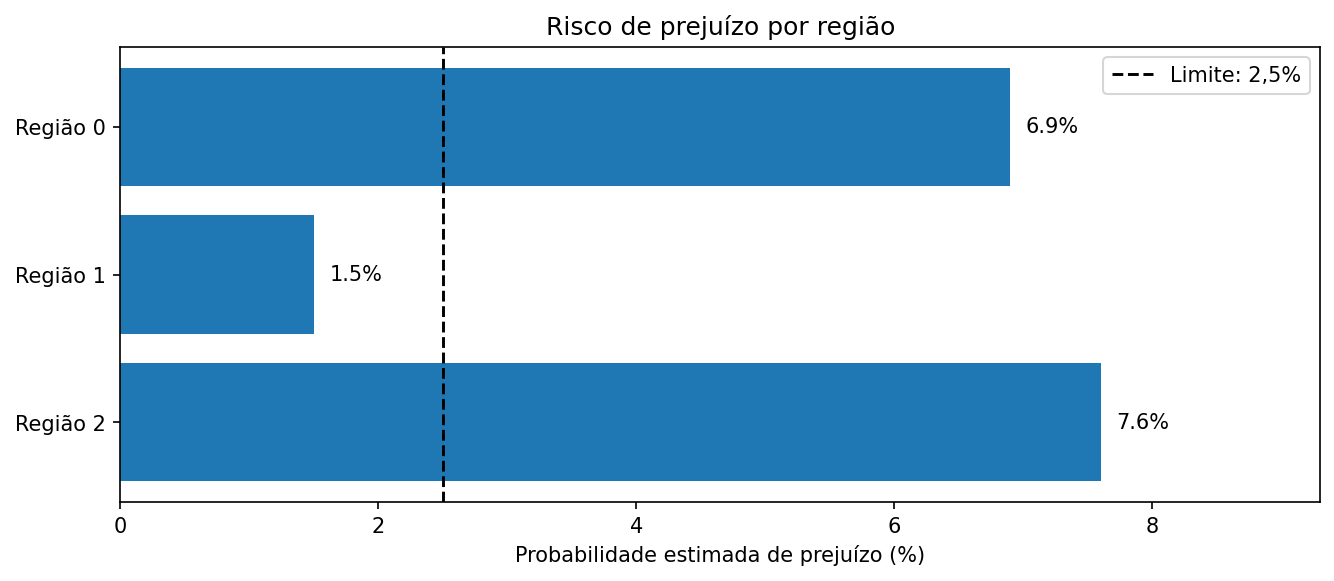

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(bootstrap_summary["Região"], bootstrap_summary["Risco de prejuízo (%)"])
ax.axvline(
    loss_risk_max * 100, color="black", linestyle="--", linewidth=1.4,
    label="Limite: 2,5%",
)
for i, risk in enumerate(bootstrap_summary["Risco de prejuízo (%)"]):
    ax.text(risk + 0.12, i, f"{risk:.1f}%", va="center")
ax.set_xlim(0, max(bootstrap_summary["Risco de prejuízo (%)"]) + 1.7)
ax.set_xlabel("Probabilidade estimada de prejuízo (%)")
ax.set_title("Risco de prejuízo por região")
ax.invert_yaxis()
ax.legend()
fig.tight_layout()
fig.savefig(figures_dir / "risco_prejuizo.png", dpi=160, bbox_inches="tight")
plt.show()

## 6. Conclusão e recomendação

**Região recomendada: Região 1.** A análise preliminar de uma seleção específica de 200 poços favorecia a Região 0, com lucro de **US$ 33,21 milhões**. Contudo, ela apresenta risco estimado de prejuízo de **6,9%** nos cenários bootstrap, acima do limite de 2,5%.

A **Região 1** foi a única a atender ao critério de risco, com **1,5% de simulações negativas** e **lucro médio simulado de US$ 4,56 milhões**. Sua faixa central de 95% dos lucros simulados foi de aproximadamente **US$ 0,34 milhão a US$ 8,52 milhões**. A Região 2 também foi rejeitada, com risco estimado de **7,6%**.

Este resultado demonstra que **a melhor decisão não é necessariamente a alternativa com o maior lucro em uma única amostra**, mas aquela que combina rentabilidade e risco de acordo com as restrições do negócio.

### Limitações e próximos passos

- **Dados sintéticos e premissas fixas:** não há variação de preços, custos operacionais, contratos ou restrições físicas de desenvolvimento.
- **Generalização:** as estimativas dependem da representatividade das amostras e da permanência das relações entre características e reservas.
- **Amostragem com reposição:** uma simulação bootstrap pode conter a mesma observação mais de uma vez; isso representa uma técnica estatística de reamostragem, não um plano operacional literal de perfuração de 200 poços físicos distintos.
- **Probabilidades aproximadas:** o risco de prejuízo deriva de 1.000 simulações, portanto possui incerteza amostral e não deve ser interpretado como probabilidade exata.
- **Identificadores:** os IDs repetidos devem ser esclarecidos antes de uso em uma operação real.

Em uma implementação real, os próximos passos seriam validar a integridade dos identificadores, analisar preços e custos variáveis, testar a robustez do modelo em novos dados e revisar a estratégia de amostragem à luz das restrições operacionais.

---
**Reprodutibilidade:** coloque os arquivos `geo_data_0.csv`, `geo_data_1.csv` e `geo_data_2.csv` em `data/` e execute **Restart & Run All**. As tabelas e imagens salvas neste arquivo foram reorganizadas com base nos resultados do notebook original aprovado; a execução completa após esta revisão requer os CSVs. Ao executar as células de gráficos, imagens serão geradas em `figures/`.